# SolarSentinel, Milestone 4: AI component and experiments

Plan: `docs/3-milestone4-plan.md`. Every number below comes from code in this notebook or from the run records in
`experiments/results/` (`m4_*.json` + `_val_preds.parquet`). All evaluation uses the gap-corrected 2015 validation set.
Replay (2016-17) labels are never loaded (`dataset.load_observations` refuses them); section 11 compares replay
*inputs* only.

Training runs are made by `python -m solarsentinel.models.m4` (this notebook reads their records, so executing it
does not retrain). `TAG` selects a run set: `None` = the final runs, `"dryrun"` = the test run on the first 1,465
cutouts.

## 1. Setup

In [1]:
import json, os, platform
import numpy as np, pandas as pd
import torch, timm, sklearn
from IPython.display import Image, display
from solarsentinel import storage
from solarsentinel.config import load_config, load_experiments
from solarsentinel.data import v2, cutouts_v2
from solarsentinel.models import m4, dataset, errors, metrics, m4_figures as figs

pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 70)
TAG = os.environ.get("M4_TAG") or None
CFG, V2 = load_experiments()["m4"], load_config()["v2"]
print(json.dumps({"code": v2.code_version(), "python": platform.python_version(), "torch": torch.__version__,
                  "timm": timm.__version__, "sklearn": sklearn.__version__, "tag": TAG}, indent=1))
print(json.dumps({"v2_rules": V2, "m4_recipe": CFG["recipe"], "m4_eval": CFG["eval"]}, indent=1))

/Users/Adam/VSCodeProjects/artificial-intelligence-systems-egn6216/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{
 "code": {
  "git_commit": "acaaed24b9b8d61e9c3d36fb4cefb0b722f2ecba",
  "dirty": true
 },
 "python": "3.13.5",
 "torch": "2.14.1",
 "timm": "1.0.30",
 "sklearn": "1.9.1",
 "tag": null
}
{
 "v2_rules": {
  "dataset_version": "v2",
  "split_gap_days": 27,
  "label_rule": {
   "train_exclude_flagged_negatives": true,
   "eval_primary": "all",
   "eval_clean_exclude": [
    "flagged_negatives",
    "quality_nonzero"
   ],
   "train_exclude_pilot_negatives": true
  },
  "cutouts": {
   "pad_to_square": true,
   "pad_value": 0.0
  }
 },
 "m4_recipe": {
  "seed": 42,
  "extra_seeds": [
   0,
   1
  ],
  "clip_percentile": 99.5,
  "clip_exclude_zero": true,
  "augment": {
   "hflip": 0.5,
   "vflip": 0.5,
   "polarity": 0.5
  },
  "epochs": 20,
  "batch_size": 32,
  "lr": 0.0001,
  "weight_decay": 0.05,
  "warmup_epochs": 1
 },
 "m4_eval": {
  "val_negatives_total": 4977,
  "bootstrap_reps": 1000,
  "bootstrap_seed": 0,
  "reliability_bins": 10,
  "calibration_folds": 2,
  "calibration_bins

## 2. v2 data and split audit (feedback item 1)

Gap rule: a later block drops every observation whose `slot_time` is earlier than the previous block's last
`slot_time` + 27 days. `processed/v2/observations.parquet` is v1 filtered by this rule; `split_audit.json` holds the
counts below and a fingerprint, and the loader checks every read against it.

In [2]:
audit = json.loads(storage.local_path(v2.audit_rel()).read_text())
display(pd.DataFrame(audit["counts"]).T)
print("first allowed slot:", audit["first_allowed_slot"])
print("HARPs shared across splits:", audit["harps_shared_across_splits"])
print("achieved minimum gap (days):", audit["achieved_min_gap_days"])
print("removed by the gap:", audit["removed_by_gap"])
print("fingerprint:", json.dumps(audit["fingerprint"], indent=1))

,observations,positives,negatives,flagged_negatives,quality_nonzero,harps,first_slot,last_slot
train,25051,1086,23965,2896,162,823,2011-01-01 00:00:00+00:00,2015-01-09 06:00:00+00:00
val,5185,208,4977,524,3,172,2015-02-05 06:00:00+00:00,2016-01-01 12:00:00+00:00
replay,5101,74,5027,100,2869,183,2016-01-28 12:00:00+00:00,2017-12-29 00:00:00+00:00


first allowed slot: {'val': '2015-02-05 06:00:00+00:00', 'replay': '2016-01-28 12:00:00+00:00'}
HARPs shared across splits: {'train&val': 0, 'train&replay': 0, 'val&replay': 0}
achieved minimum gap (days): {'train->val': 27.0, 'val->replay': 27.0}
removed by the gap: {'train': {'observations': 0, 'positives': 0}, 'val': {'observations': 652, 'positives': 25}, 'replay': {'observations': 376, 'positives': 3}}
fingerprint: {
 "source": "processed/v1/observations.parquet",
 "source_sha256": "382c31b023be6176c2b66505cfa0397ba955091d3fcad437d7eb0043e6077b81",
 "v2_rule_sha256": "4ebbec5de9cab8d20eef4162dee9a1b717af5d6c3c115827bf1fe8ec30c884f5",
 "output": "processed/v2/observations.parquet",
 "output_sha256": "8e8c4019e049a9ec6f7de10a78051d43a4ac6ebbc73849ca4ff69b0d6f3e4f89",
 "rows": 35337,
 "git_commit": "acaaed24b9b8d61e9c3d36fb4cefb0b722f2ecba",
 "dirty": false
}


**First-exploration numbers before and after the gap.** No retraining: each saved `fme_*_val_preds.parquet` is
filtered to the val rows that survive the gap; the max-TSS threshold is re-picked on those cases (same convention as
the original runs).

In [3]:
FME = m4.rescore_fme()
FME.round(3)

,run_id,seed,n_630,pos_630,tss_630,tss_ci_630,auc_630,n_gap,pos_gap,flaring_harps_gap,tss_gap,tss_ci_gap,auc_gap,threshold_gap
0,fme_A_resnet18_s0,0,630,210,0.629,"[0.4752095844869991, 0.7290093443495225]",0.874,569,189,27,0.646,"[0.5065203079597344, 0.7369276330934685]",0.876,0.459
1,fme_A_resnet18_s1,1,630,210,0.617,"[0.4935520382716678, 0.7037858555227848]",0.869,569,189,27,0.620,"[0.45307016055055693, 0.7313765406552702]",0.869,0.514
2,fme_A_resnet18_s42,42,630,210,0.648,"[0.5198960804782995, 0.7441250518237212]",0.878,569,189,27,0.647,"[0.5077727249786073, 0.7361458296458175]",0.878,0.498
3,fme_B_deit_tiny_s0,0,630,210,0.602,"[0.49461593183492386, 0.6864613196859881]",0.873,569,189,27,0.620,"[0.47154866513824684, 0.7320354331440563]",0.883,0.322
4,fme_B_deit_tiny_s1,1,630,210,0.652,"[0.5248094632354412, 0.7388009761358633]",0.878,569,189,27,0.686,"[0.5623590580452091, 0.7680987749387793]",0.884,0.245
5,fme_B_deit_tiny_s42,42,630,210,0.626,"[0.5103402748775632, 0.7119319757750981]",0.873,569,189,27,0.638,"[0.4801768359748292, 0.7506030993818231]",0.875,0.329
6,fme_C_A_opt3_s42,42,630,210,0.633,"[0.4916025014370046, 0.7310721591264545]",0.865,569,189,27,0.644,"[0.48505425366307153, 0.7473380496803238]",0.864,0.522


## 3. Frozen label rule and counts (feedback item 2)

| Use | Rule |
|---|---|
| Training | exclude flagged negatives (`has_unattributed_mx & label == 0`); keep `quality_nonzero` rows; pilot-week negatives excluded (developer decision 2026-11-02) |
| Evaluation, primary | every gap-corrected val case that has an image |
| Evaluation, secondary ("clean") | primary minus flagged negatives and `quality_nonzero` rows |

In [4]:
_, META = dataset.load_cutouts(cutouts_v2.pad_prefix(), version="v2")
(_, MTR), (_, MVA) = m4.load_arm("pad")
OBS = dataset.load_observations("v2")

def counts(m):
    return {"cases": len(m), "positives": int(m.label.sum()), "negatives": int((m.label == 0).sum()),
            "flagged_negatives": int((m.has_unattributed_mx & (m.label == 0)).sum()),
            "quality_nonzero": int(m.quality_nonzero.sum()), "harps": m.HARPNUM.nunique(),
            "flaring_harps": m.HARPNUM[m.label == 1].nunique()}

tr_disk = META[META.split == "train"]
LABEL_COUNTS = pd.DataFrame({
    "train, all v2 rows": counts(OBS[OBS.split == "train"]),
    "train, images on disk": counts(tr_disk),
    "train, used (frozen rule)": counts(MTR),
    "val, all v2 rows": counts(OBS[OBS.split == "val"]),
    "val primary (cases with image)": counts(MVA),
    "val clean": counts(MVA[dataset.clean_mask(MVA)]),
}).T
display(LABEL_COUNTS)
print("train images from the pilot week:", int((tr_disk.fits_root == "pilot").sum()),
      "| pilot negatives excluded from training:", int(((tr_disk.fits_root == "pilot") & (tr_disk.label == 0)).sum()))

,cases,positives,negatives,flagged_negatives,quality_nonzero,harps,flaring_harps
"train, all v2 rows",25051,1086,23965,2896,162,823,133
"train, images on disk",3289,1072,2217,163,14,727,133
"train, used (frozen rule)",3117,1072,2045,0,14,720,133
"val, all v2 rows",5185,208,4977,524,3,172,27
val primary (cases with image),626,208,418,47,1,151,27
val clean,578,207,371,0,0,143,27


train images from the pilot week: 126 | pilot negatives excluded from training: 109


**What the clean subset leaves out (Should).** Flagged vs clean negatives over all train+val v2 rows, on three SHARP
inputs and on the share in high-activity months (months in the top quartile of positive rate, train+val).

In [5]:
neg = OBS[OBS.label == 0].copy()
month = OBS.slot_time.dt.tz_localize(None).dt.to_period("M")
rate = OBS.groupby(month).label.mean()
high = set(rate[rate >= rate.quantile(0.75)].index)
neg["high_activity_month"] = month[neg.index].isin(high)
FLAG_CMP = neg.groupby(neg.has_unattributed_mx.rename("flagged")).agg(
    n=("HARPNUM", "size"), USFLUX_median=("USFLUX", "median"), AREA_ACR_median=("AREA_ACR", "median"),
    TOTUSJH_median=("TOTUSJH", "median"), share_in_high_activity_months=("high_activity_month", "mean"))
display(FLAG_CMP)
print("high-activity months:", sorted(str(m) for m in high))

,n,USFLUX_median,AREA_ACR_median,TOTUSJH_median,share_in_high_activity_months
flagged,,,,,
False,25522,5.780278e+21,280.886490,377.9860,0.230664
True,3420,6.283485e+21,286.959244,405.4675,0.494737


high-activity months: ['2011-02', '2011-03', '2011-09', '2012-06', '2012-07', '2013-05', '2013-10', '2013-11', '2014-02', '2014-03', '2014-06', '2014-10', '2014-12', '2015-01', '2015-03', '2015-09']


## 4. Padding inspection (feedback item 3)

v2 rule: zero-pad the FITS array to a square (centered), then the v1 NaN fill and anti-aliased resize to 128x128
float16. Inspected: the 10 thinnest regions (largest long/short side ratio, one snapshot per HARP) and every cutout
with `nan_fraction > 0`. The figure shows 6 thin regions and the 3 HARPs with the most NaN pixels.

,HARPNUM,T_REC,orig_ny,orig_nx,aspect,short_side_px,pad_fraction,nan_fraction
0,2758,2013.05.23_05:48:00_TAI,383,2101,5.486,23.334,0.818,0.000
1,371,2011.02.10_05:48:00_TAI,151,655,4.338,29.508,0.769,0.000
2,1093,2011.11.20_12:00:00_TAI,643,2694,4.190,30.551,0.761,0.145
3,2832,2013.06.06_00:00:00_TAI,240,1003,4.179,30.628,0.761,0.000
4,2760,2013.05.23_12:00:00_TAI,546,2213,4.053,31.581,0.753,0.000
5,4678,2014.10.17_00:00:00_TAI,374,1496,4.000,32.000,0.750,0.000
6,1249,2011.12.28_12:00:00_TAI,218,868,3.982,32.147,0.749,0.000
7,2329,2012.12.31_05:48:00_TAI,328,1284,3.915,32.698,0.745,0.000
8,1996,2012.09.01_05:48:00_TAI,271,1054,3.889,32.911,0.743,0.000
9,2597,2013.04.04_17:48:00_TAI,386,1486,3.850,33.249,0.740,0.000


{
 "figure": "/Users/Adam/VSCodeProjects/artificial-intelligence-systems-egn6216/docs/figures/m4/fig2_pad_vs_stretch.png",
 "n_thin_shown": 10,
 "n_nan_cutouts": 127,
 "n_shown": 9,
 "aspect_ge_2": 2106,
 "aspect_ge_4": 35,
 "short_side_px_min": 23.3,
 "short_side_px_at_aspect_ge_2_median": 53.3,
 "nan_fraction_max": 0.4817,
 "nan_and_pad_both_zero": "NaN pixels are filled with nan_fill = 0 and padding is pad_value = 0: the model cannot tell them apart"
}
cutouts per FITS root: {'full': 3789, 'pilot': 126} | pad_fraction median 0.511
manifest: processed/v2/manifest.json sha256 10816699b251c80f94479a133e0d83f0d8b66e0e48da64459d9b07924ddf580a | files 125 | commit acaaed24b9b8d61e9c3d36fb4cefb0b722f2ecba dirty False


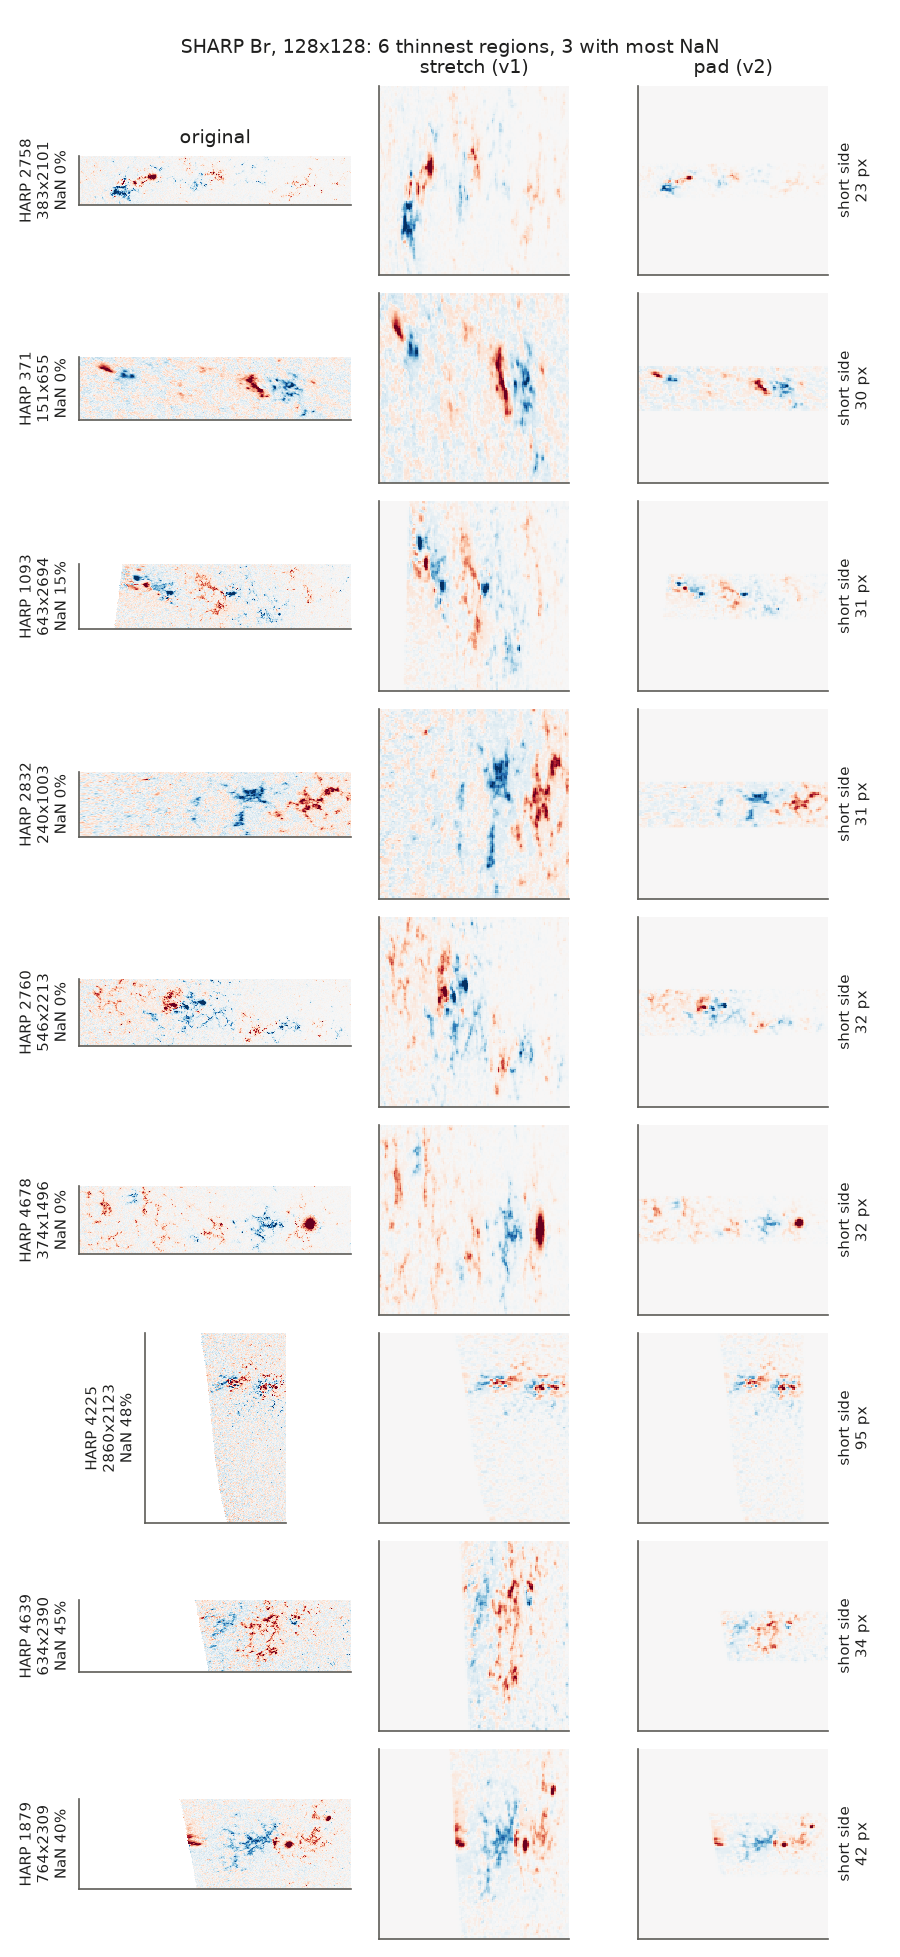

In [6]:
IDX_PAD = pd.read_parquet(storage.local_path(f"{cutouts_v2.pad_prefix()}/index.parquet"))
INSP = cutouts_v2.inspect(IDX_PAD, figs.fig_dir() / "fig2_pad_vs_stretch.png")
display(pd.DataFrame(INSP.pop("thinnest")))
print(json.dumps(INSP, indent=1))
print("cutouts per FITS root:", IDX_PAD.fits_root.value_counts().to_dict(), "| pad_fraction median",
      round(float(IDX_PAD.pad_fraction.median()), 3))
MAN_PATH = storage.local_path(f"{v2.v2_prefix()}/manifest.json")
MAN = json.loads(MAN_PATH.read_text())
print("manifest:", f"{v2.v2_prefix()}/manifest.json", "sha256", storage.sha256(MAN_PATH), "| files", len(MAN["files"]),
      "| commit", MAN["git_commit"], "dirty", MAN["dirty"])
display(Image(str(figs.fig_dir() / "fig2_pad_vs_stretch.png"), width=420))

## 5. Baseline: persistence (PR1)

"Flare" at t if the same HARP had an attributed flare >= M1.0 peaking in (t - 24 h, t]: the label logic mirrored
backwards (same links, same science flux scale). It needs no images, so it also shows that the parameter-only path
works. `check_mirror` rebuilds the forward labels with the same code: it must reproduce `label` exactly.

In [7]:
from solarsentinel.models import baseline
print("forward-label mismatches when the same code is run forwards (train+val):", baseline.check_mirror(OBS))
R2 = m4.e2(TAG)
CASES_KEYS = m4.load_run(R2["run_ids"]["pad"][0])[1] if R2["run_ids"]["pad"] else None
PERS = m4.persistence_rows(CASES_KEYS)
PERS_T = pd.DataFrame({k: {kk: vv for kk, vv in v.items() if kk != "bootstrap"} | {"tss_ci95": v["bootstrap"]["tss_ci95"]}
                       for k, v in PERS.items()}).T
PERS_T

forward-label mismatches when the same code is run forwards (train+val): 0


,n,n_pos,n_flaring_harps,tp,fp,fn,tn,pod,pofd,tss,precision_corrected,tss_ci95
full_val,5185,208,27,75,125,133,4852,0.360577,0.025116,0.335461,0.375,"[0.15586347577681317, 0.4679575147525038]"
model_cases,626,208,27,75,11,133,407,0.360577,0.026316,0.334261,0.364124,"[0.14900015317302268, 0.4684311314333207]"


## Decision rules (pre-registered before the final runs)

Shared recipe: v2 data and gap, frozen label rule, 20 epochs, final epoch evaluated (no early stopping), flips +
polarity flip, `pos_weight = n_neg/n_pos`, AdamW lr 1e-4 wd 0.05, cosine with 1 warmup epoch, batch 32, fp32 on
`mps`, seeds 42, 0, 1. Input `clip(Br, ±c)/c` with `c` = 99.5th percentile of |Br| over the arm's non-zero train
pixels (developer decision 2026-11-02, so padding zeros do not lower `c`). Every run is scored at its own max-TSS
threshold on val.

- **E2 (pad vs stretch, ResNet-18).** Adopt pad unless clearly worse: mean-over-seeds TSS difference (pad -
  stretch) < -0.02 **and** its 95% HARP-bootstrap CI excludes 0. Also reported: ROC-AUC, TSS and recall on thin
  regions (long/short side >= 2).
- **E1 (ResNet-18 vs DeiT-Tiny, on the E2 winner).** If the 95% CI of the mean TSS difference excludes 0, the
  higher TSS wins. Otherwise, in order: (1) E3 calibration result (the model whose seed-42 scores reach probability
  mode), (2) size and CPU latency against Section 2.3 (< 50 MB, < 100 ms per region), (3) implementation complexity
  (ResNet-18: plain CNN, any input size; DeiT-Tiny needs a resized patch grid). The rule that decided is recorded.
- **E3 (calibration of the selected model, seed 42).** None vs Platt vs isotonic, HARP-grouped 2-fold
  cross-fitting within val, prevalence weights. Probability mode if a calibration method passes all three PR2
  checks (mean p / observed in [0.5, 2]; calibration-slope 95% CI contains 1; 5 equal-count bins, at most one bin
  whose observed-frequency CI misses its mean p); the passing method with the higher weighted BSS is used. Else
  ranking mode.
- **Confidently wrong** (error analysis): calibrated p > 0.9 for a false positive, < 0.05 for a false negative.

## 6. E2: does keeping the regions' shape (pad) beat stretching?

In [8]:
COLS = ["run_id", "seed", "tss", "tss_ci95", "roc_auc", "pr_auc_corrected", "threshold", "pod", "pofd", "thin_n",
        "thin_pos", "thin_tss", "thin_recall", "clip_c", "n_train", "n_train_pos", "n_val", "n_val_pos", "epoch_s_median"]

def show(name, s):
    print(name, {k: [round(v[0], 3), round(v[1], 3)] for k, v in s["mean_sd"].items()}, "(mean, sd over seeds)")
    display(s["runs"][COLS].round(3))

for arm in ("pad", "stretch"):
    if arm in R2:
        show(f"ResNet-18 {arm}", R2[arm])
print(json.dumps(R2.get("diff_pad_minus_stretch"), indent=1))
print("E2 winner:", R2.get("winner"), "| rule:", R2.get("rule"))

ResNet-18 pad {'tss': [0.692, 0.014], 'roc_auc': [0.902, 0.004], 'pr_auc_corrected': [0.349, 0.015], 'thin_tss': [0.633, 0.022], 'thin_recall': [0.847, 0.015], 'epoch_s_median': [5.51, 0.01]} (mean, sd over seeds)


,run_id,seed,tss,tss_ci95,roc_auc,pr_auc_corrected,threshold,pod,pofd,thin_n,thin_pos,thin_tss,thin_recall,clip_c,n_train,n_train_pos,n_val,n_val_pos,epoch_s_median
0,m4_E2_resnet18_pad_s42,42,0.693,"[0.5727075935710464, 0.7839020840525879]",0.900,0.344,0.319,0.841,0.148,354,139,0.648,0.835,980.5,3117,1072,626,208,5.50
1,m4_E2_resnet18_pad_s0,0,0.676,"[0.5601133771424018, 0.7571784315613765]",0.900,0.338,0.222,0.885,0.208,354,139,0.607,0.863,980.5,3117,1072,626,208,5.51
2,m4_E2_resnet18_pad_s1,1,0.705,"[0.5867391122731912, 0.795318982624387]",0.907,0.366,0.428,0.856,0.151,354,139,0.642,0.842,980.5,3117,1072,626,208,5.52


ResNet-18 stretch {'tss': [0.705, 0.013], 'roc_auc': [0.898, 0.002], 'pr_auc_corrected': [0.466, 0.015], 'thin_tss': [0.648, 0.028], 'thin_recall': [0.811, 0.021], 'epoch_s_median': [5.587, 0.086]} (mean, sd over seeds)


,run_id,seed,tss,tss_ci95,roc_auc,pr_auc_corrected,threshold,pod,pofd,thin_n,thin_pos,thin_tss,thin_recall,clip_c,n_train,n_train_pos,n_val,n_val_pos,epoch_s_median
0,m4_E2_resnet18_stretch_s42,42,0.691,"[0.5483897093931503, 0.7868773307083261]",0.900,0.460,0.400,0.817,0.127,354,139,0.617,0.799,1049.0,3117,1072,626,208,5.57
1,m4_E2_resnet18_stretch_s0,0,0.710,"[0.5782949528991469, 0.7958255861781666]",0.897,0.482,0.404,0.837,0.127,354,139,0.653,0.835,1049.0,3117,1072,626,208,5.51
2,m4_E2_resnet18_stretch_s1,1,0.714,"[0.565669086654649, 0.8126540046435968]",0.898,0.454,0.602,0.798,0.084,354,139,0.673,0.799,1049.0,3117,1072,626,208,5.68


{
 "diff_mean_tss": -0.013349589007483842,
 "diff_ci95": [
  -0.058823613390534886,
  0.042023075897025544
 ],
 "share_b_better": 0.313,
 "reps_used": 1000,
 "seed": 0,
 "n": 626,
 "n_pos": 208,
 "n_harps": 151
}
E2 winner: pad | rule: adopt pad unless mean TSS diff (pad - stretch) < -0.02 and its 95% CI excludes 0


## 7. E1: which pretrained model, and does it beat persistence?

ResNet-18 pad {'tss': [0.692, 0.014], 'roc_auc': [0.902, 0.004], 'pr_auc_corrected': [0.349, 0.015], 'thin_tss': [0.633, 0.022], 'thin_recall': [0.847, 0.015], 'epoch_s_median': [5.51, 0.01]} (mean, sd over seeds)


,run_id,seed,tss,tss_ci95,roc_auc,pr_auc_corrected,threshold,pod,pofd,thin_n,thin_pos,thin_tss,thin_recall,clip_c,n_train,n_train_pos,n_val,n_val_pos,epoch_s_median
0,m4_E2_resnet18_pad_s42,42,0.693,"[0.5727075935710464, 0.7839020840525879]",0.900,0.344,0.319,0.841,0.148,354,139,0.648,0.835,980.5,3117,1072,626,208,5.50
1,m4_E2_resnet18_pad_s0,0,0.676,"[0.5601133771424018, 0.7571784315613765]",0.900,0.338,0.222,0.885,0.208,354,139,0.607,0.863,980.5,3117,1072,626,208,5.51
2,m4_E2_resnet18_pad_s1,1,0.705,"[0.5867391122731912, 0.795318982624387]",0.907,0.366,0.428,0.856,0.151,354,139,0.642,0.842,980.5,3117,1072,626,208,5.52


DeiT-Tiny pad {'tss': [0.635, 0.033], 'roc_auc': [0.876, 0.01], 'pr_auc_corrected': [0.335, 0.017], 'thin_tss': [0.609, 0.025], 'thin_recall': [0.82, 0.043], 'epoch_s_median': [8.01, 0.075]} (mean, sd over seeds)


,run_id,seed,tss,tss_ci95,roc_auc,pr_auc_corrected,threshold,pod,pofd,thin_n,thin_pos,thin_tss,thin_recall,clip_c,n_train,n_train_pos,n_val,n_val_pos,epoch_s_median
0,m4_E1_deit_tiny_pad_s42,42,0.597,"[0.4362581786142972, 0.7149412825033986]",0.870,0.328,0.041,0.760,0.163,354,139,0.586,0.777,980.5,3117,1072,626,208,7.94
1,m4_E1_deit_tiny_pad_s0,0,0.655,"[0.5107480533155877, 0.7480623403167586]",0.887,0.354,0.027,0.812,0.158,354,139,0.606,0.820,980.5,3117,1072,626,208,8.00
2,m4_E1_deit_tiny_pad_s1,1,0.652,"[0.5230729807563265, 0.735320061005117]",0.870,0.322,0.024,0.837,0.184,354,139,0.635,0.863,980.5,3117,1072,626,208,8.09


{
 "diff_deit_minus_resnet": {
  "diff_mean_tss": -0.05689485952643836,
  "diff_ci95": [
   -0.1334771536159098,
   -0.0012647677462617223
  ],
  "share_b_better": 0.022,
  "reps_used": 1000,
  "seed": 0,
  "n": 626,
  "n_pos": 208,
  "n_harps": 151
 },
 "tiebreak_calibration_pass": null,
 "tiebreak_size_latency_meets_targets": null,
 "selected": "A",
 "decided_by": "TSS difference (CI excludes 0)"
}


2026-11-02 21:10:42 - timm.models._builder - INFO: Loading pretrained weights from Hugging Face hub (timm/resnet18.a1_in1k)


... (8 outputs left out)

2026-11-02 21:10:49 - timm.layers.pos_embed - INFO: Resized position embedding: (14, 14) to (8, 8).


2026-11-02 21:10:49 - timm.models._builder - INFO: Converted input conv patch_embed.proj pretrained weights from 3 to 1 channel(s)


2026-11-02 21:10:49 - timm.models._builder - INFO: Missing keys (head.weight, head.bias) discovered while loading pretrained weights. This is expected if model is being adapted.


{
 "A": {
  "model": "resnet18.a1_in1k",
  "state_dict_mb": 44.76,
  "params": 11170753,
  "latency": [
   {
    "batch": 1,
    "median_ms": 5.69,
    "p90_ms": 5.84,
    "per_region_ms": 5.69,
    "threads": 8,
    "reps": 200
   },
   {
    "batch": 15,
    "median_ms": 27.03,
    "p90_ms": 28.04,
    "per_region_ms": 1.8,
    "threads": 8,
    "reps": 200
   }
  ]
 },
 "B": {
  "model": "deit_tiny_patch16_224.fb_in1k",
  "state_dict_mb": 21.66,
  "params": 5400961,
  "latency": [
   {
    "batch": 1,
    "median_ms": 6.23,
    "p90_ms": 11.45,
    "per_region_ms": 6.23,
    "threads": 8,
    "reps": 200
   },
   {
    "batch": 15,
    "median_ms": 17.05,
    "p90_ms": 20.07,
    "per_region_ms": 1.14,
    "threads": 8,
    "reps": 200
   }
  ]
 }
}


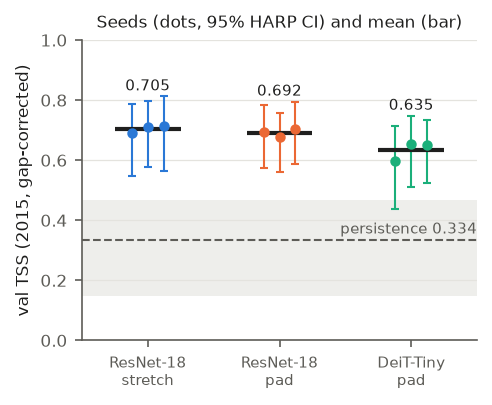

In [9]:
WIN = R2.get("winner", "pad")
E1 = m4.e1(WIN, TAG)
for k, name in (("A", "ResNet-18"), ("B", "DeiT-Tiny")):
    if k in E1:
        show(f"{name} {WIN}", E1[k])
print(json.dumps({k: E1.get(k) for k in ("diff_deit_minus_resnet", "tiebreak_calibration_pass",
                                          "tiebreak_size_latency_meets_targets", "selected", "decided_by")}, indent=1, default=str))
VS_PERS = {k: m4.paired_vs_persistence(r) for k, r in E1["run_ids"].items() if r}
print("model - persistence on the same val cases (seed-mean TSS, HARP bootstrap):", json.dumps(VS_PERS, indent=1))
SM = {k: m4.system_measures(k) for k in ("A", "B")}
print(json.dumps(SM, indent=1))
ARMS_FIG = {f"ResNet-18\nstretch": R2["stretch"]["runs"]} if "stretch" in R2 else {}
if "pad" in R2:
    ARMS_FIG["ResNet-18\npad"] = R2["pad"]["runs"]
if "B" in E1:
    ARMS_FIG[f"DeiT-Tiny\n{WIN}"] = E1["B"]["runs"]
display(Image(str(figs.experiments(ARMS_FIG, PERS["model_cases"])), width=380))

## 8. E3: can the selected model's scores be shown as probabilities?

selected run: m4_E2_resnet18_pad_s42 | n 626 positives 208 | weights {'positive': 1.0, 'negative': 11.9066985645933}


,mean_p,observed_rate,ratio,check1_ratio_pass,slope,slope_ci95,check2_slope_pass,bin_misses,check3_bins_pass,all_pass,brier,bss,threshold,tss_at_threshold,roc_auc
none,0.154537,0.040116,3.852286,False,0.705974,"[0.5477281640437118, 0.9228837887835861]",False,4,False,False,0.075765,-0.967598,0.319063,0.693021,0.899786
platt,0.03847,0.040116,0.958983,True,0.991801,"[0.7538788851891873, 1.330145248423493]",True,0,True,True,0.031929,0.170823,0.048124,0.690651,0.898785
isotonic,0.042909,0.040116,1.069633,True,0.384847,"[0.19329715379953638, 1.0926169548274118]",True,0,True,True,0.032647,0.152158,0.055496,0.693021,0.892091


none


,bin,n,n_pos,p_mean,observed,observed_ci95,miss
0,0,126,3,0.0047,0.0020,"[0.0, 0.005523296228929292]",False
1,1,125,8,0.0207,0.0057,"[0.0013517303538018166, 0.012291773514716187]",True
2,2,125,20,0.1035,0.0157,"[0.0068717531683048835, 0.02781492492460262]",True
3,3,125,72,0.4728,0.1024,"[0.05658806050388916, 0.16162994057882366]",True
4,4,125,105,0.8789,0.3060,"[0.16262515150134238, 0.48029557066717743]",True


platt


,bin,n,n_pos,p_mean,observed,observed_ci95,miss
0,0,126,3,0.0020,0.0020,"[0.0, 0.005523296228929293]",False
1,1,125,8,0.0060,0.0057,"[0.0013419780692531305, 0.012407552823094742]",False
2,2,125,20,0.0197,0.0157,"[0.007022660543076615, 0.027503730354269604]",False
3,3,125,75,0.0772,0.1119,"[0.06174689304748314, 0.17553480100526098]",False
4,4,125,102,0.2960,0.2714,"[0.13994718692946964, 0.44922186858524815]",False


isotonic


,bin,n,n_pos,p_mean,observed,observed_ci95,miss
0,0,126,5,0.0000,0.0035,"[0.0, 0.008330169547301224]",False
1,1,125,9,0.0047,0.0065,"[0.0018205674217730216, 0.013984577420146456]",False
2,2,125,16,0.0162,0.0122,"[0.005801268077311722, 0.021169628472274604]",False
3,3,125,76,0.1059,0.1153,"[0.06541061592388583, 0.1754511053931102]",False
4,4,125,102,0.3322,0.2714,"[0.13296031644659434, 0.43691099400309513]",False


dashboard mode: probability | method: platt | probability mode if a calibration method (cross-fitted) passes all three PR2 checks; the passing method with the higher weighted BSS is used; else ranking mode


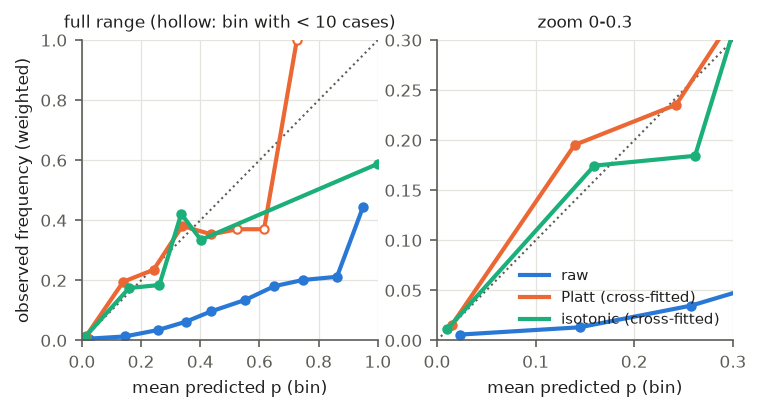

In [10]:
SEL = E1.get("selected", "A")
SEL_RID = m4.run_id("E2" if SEL == "A" else "E1", SEL, WIN, CFG["recipe"]["seed"], TAG)
E3 = m4.e3(SEL_RID)
print("selected run:", SEL_RID, "| n", E3["n"], "positives", E3["n_pos"], "| weights", E3["weights"])
E3_T = pd.DataFrame({m: {k: v for k, v in r.items() if k != "bins"} for m, r in E3["methods"].items()}).T
display(E3_T[["mean_p", "observed_rate", "ratio", "check1_ratio_pass", "slope", "slope_ci95", "check2_slope_pass",
              "bin_misses", "check3_bins_pass", "all_pass", "brier", "bss", "threshold", "tss_at_threshold", "roc_auc"]])
for m, r in E3["methods"].items():
    print(m); display(pd.DataFrame(r["bins"]).round(4))
print("dashboard mode:", E3["mode"], "| method:", E3["chosen_method"], "|", E3["rule"])
_, SEL_PREDS = m4.load_run(SEL_RID)
from solarsentinel.models import calibration as cal
W = np.where(SEL_PREDS.label.to_numpy() == 1, E3["weights"]["positive"], E3["weights"]["negative"])
curves = {"raw": SEL_PREDS.p.to_numpy().astype(float), "Platt (cross-fitted)": E3["p_cal"]["platt"],
          "isotonic (cross-fitted)": E3["p_cal"]["isotonic"]}
display(Image(str(figs.reliability(SEL_PREDS.label.to_numpy(), W, curves, CFG["eval"]["reliability_bins"])), width=520))

## 9. Error analysis (selected model, seed 42, at its threshold)

threshold 0.3191 | outcomes {'TN': 356, 'TP': 175, 'FP': 62, 'FN': 33} | p_cal from platt


,error,category,n,of,share
0,FN,flare M1.0-1.9,20,33,0.606
1,FN,flare M2-4.9,11,33,0.333
2,FN,flare >=M5,2,33,0.061
3,FP,negative C-flare,32,62,0.516
4,FP,negative quiet,30,62,0.484
5,FN,flagged_negative,0,33,0.000
6,FN,multi_noaa,4,33,0.121
7,FN,thin,23,33,0.697
8,FN,nan,0,33,0.000
9,FN,far_lon,10,33,0.303


largest category: ('FP', 'thin')


/var/folders/vq/hbwc6_v92sg0d1qr62bc4_800000gn/T/ipykernel_91084/1310810479.py:16: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(CASES[CASE_COLS].round(3))


,why,outcome,p,p_cal,HARPNUM,NOAA_AR,slot_time,label_class,has_unattributed_mx,multi_noaa,quality_nonzero,USFLUX,aspect,nan_fraction,LON_FWT,persistence
0,confident FN,FN,0.003,0.001,6060,12441,2015-11-01 18:00:00+00:00,M1.0,False,False,False,6.476014e+20,1.675,0.0,15.076,0
1,confident FN,FN,0.007,0.002,5461,12332,2015-04-21 12:00:00+00:00,M1.5,True,False,False,1.164230e+21,2.640,0.0,12.343,0
2,confident FN,FN,0.007,0.003,5461,12332,2015-04-22 00:00:00+00:00,M1.5,False,False,False,1.137354e+21,2.640,0.0,19.076,0
3,confident FN,FN,0.015,0.004,5990,12428,2015-09-28 06:00:00+00:00,M1.0,True,False,False,9.116907e+20,2.521,0.0,53.924,0
4,confident FN,FN,0.017,0.005,5990,12428,2015-09-28 00:00:00+00:00,M1.0,True,False,False,1.161050e+21,2.521,0.0,51.055,0
5,confident FP,FP,0.974,0.604,6206,12473,2015-12-28 06:00:00+00:00,C5.8,True,False,False,2.643422e+22,2.400,0.0,6.821,1
6,confident FP,FP,0.966,0.427,5541,12339,2015-05-08 18:00:00+00:00,C4.3,False,True,False,6.785875e+22,2.713,0.0,-38.412,0
7,confident FP,FP,0.957,0.509,6027,12436,2015-10-20 06:00:00+00:00,C8.9,False,False,False,3.247155e+22,2.439,0.0,-43.203,0
8,confident FP,FP,0.950,0.363,5144,12280,2015-02-08 06:00:00+00:00,C4.5,False,False,False,1.439920e+22,1.289,0.0,15.885,0
9,confident FP,FP,0.937,0.434,6027,12436,2015-10-19 06:00:00+00:00,C5.6,False,False,False,3.566761e+22,2.439,0.0,-56.126,0


confidently wrong: 33 | FP > 0.9: 0 | FN < 0.05: 33 | all FNs: 33


/var/folders/vq/hbwc6_v92sg0d1qr62bc4_800000gn/T/ipykernel_91084/1310810479.py:20: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(CW[CASE_COLS[1:]].round(3))


,outcome,p,p_cal,HARPNUM,NOAA_AR,slot_time,label_class,has_unattributed_mx,multi_noaa,quality_nonzero,USFLUX,aspect,nan_fraction,LON_FWT,persistence
532,FN,0.003,0.001,6060,12441,2015-11-01 18:00:00+00:00,M1.0,False,False,False,6.476014e+20,1.675,0.0,15.076,0
171,FN,0.007,0.002,5461,12332,2015-04-21 12:00:00+00:00,M1.5,True,False,False,1.164230e+21,2.640,0.0,12.343,0
176,FN,0.007,0.003,5461,12332,2015-04-22 00:00:00+00:00,M1.5,False,False,False,1.137354e+21,2.640,0.0,19.076,0
466,FN,0.015,0.004,5990,12428,2015-09-28 06:00:00+00:00,M1.0,True,False,False,9.116907e+20,2.521,0.0,53.924,0
463,FN,0.017,0.005,5990,12428,2015-09-28 00:00:00+00:00,M1.0,True,False,False,1.161050e+21,2.521,0.0,51.055,0
531,FN,0.023,0.006,6060,12441,2015-11-01 12:00:00+00:00,M1.0,False,False,False,7.242984e+20,1.675,0.0,11.983,0
174,FN,0.024,0.006,5461,12332,2015-04-21 18:00:00+00:00,M1.5,True,False,False,1.018810e+21,2.640,0.0,16.380,0
164,FN,0.021,0.007,5456,12325,2015-04-21 00:00:00+00:00,M2.5,True,False,False,1.082781e+22,2.162,0.0,8.106,0
430,FN,0.030,0.009,5956,12415,2015-09-20 18:00:00+00:00,M3.1,False,False,False,2.268214e+22,2.383,0.0,49.608,0
173,FN,0.034,0.009,5456,12325,2015-04-21 18:00:00+00:00,M2.5,True,False,False,1.326329e+22,2.162,0.0,18.425,0


{
 "recall_by_flare_class": {
  "M1.0-1.9": {
   "n": 101,
   "recall": 0.801980198019802
  },
  "M2-4.9": {
   "n": 55,
   "recall": 0.8
  },
  ">=M5": {
   "n": 52,
   "recall": 0.9615384615384616
  }
 },
 "recall_by_usflux_tercile": {
  "low": {
   "n": 70,
   "recall": 0.5571428571428572,
   "usflux_range": [
    6.476014e+20,
    2.342232e+22
   ]
  },
  "mid": {
   "n": 69,
   "recall": 0.9855072463768116,
   "usflux_range": [
    2.354212e+22,
    3.853554e+22
   ]
  },
  "high": {
   "n": 69,
   "recall": 0.9855072463768116,
   "usflux_range": [
    3.874148e+22,
    8.902136e+22
   ]
  }
 },
 "false_alarm_by_negative_type": {
  "C-flare": {
   "n": 66,
   "false_alarm_rate": 0.48484848484848486
  },
  "quiet": {
   "n": 352,
   "false_alarm_rate": 0.08522727272727272
  }
 }
}


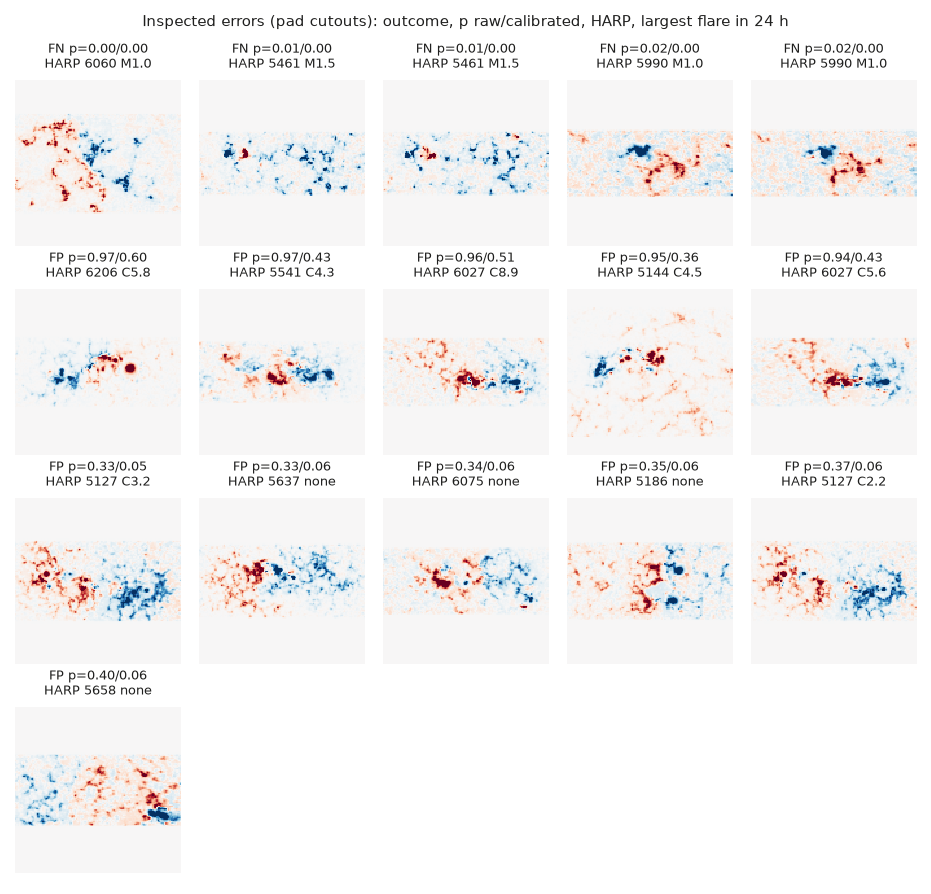

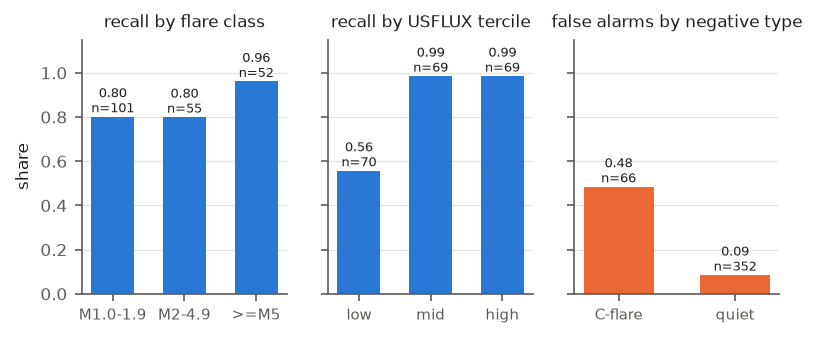

In [11]:
SEL_REC, _ = m4.load_run(SEL_RID)
THR = SEL_REC["metrics"]["threshold"]
PCAL = E3["p_cal"][E3["chosen_method"]] if E3["chosen_method"] else None  # ranking mode: raw scores only
IDX_SEL = pd.read_parquet(storage.local_path(f"{m4.arm_prefix(WIN)}/index.parquet"))
T = errors.tag(SEL_PREDS, IDX_SEL, THR, thin_aspect=CFG["eval"]["thin_aspect"], p_cal=PCAL)
print("threshold", round(THR, 4), "| outcomes", T.outcome.value_counts().to_dict(),
      "| p_cal from", E3["chosen_method"] or "none (raw scores used)")
CC = errors.category_counts(T)
display(CC)
cand = CC[CC.category != "persistence_agrees"].sort_values("n", ascending=False).iloc[0]
LARGEST = (cand.error, cand.category)
print("largest category:", LARGEST)
CASES = errors.inspect_cases(T, LARGEST)
CASE_COLS = ["why", "outcome", "p", "p_cal", "HARPNUM", "NOAA_AR", "slot_time", "label_class", "has_unattributed_mx",
             "multi_noaa", "quality_nonzero", "USFLUX", "aspect", "nan_fraction", "LON_FWT", "persistence"]
display(CASES[CASE_COLS].round(3))
CW = errors.confidently_wrong(T, "p_cal" if PCAL is not None else "p")
print("confidently wrong:", len(CW), "| FP > 0.9:", int((CW.outcome == "FP").sum()), "| FN < 0.05:", int((CW.outcome == "FN").sum()),
      "| all FNs:", int((T.outcome == "FN").sum()))
display(CW[CASE_COLS[1:]].round(3))
PAT = errors.pattern(T)
print(json.dumps(PAT, indent=1))
display(Image(str(figs.error_gallery(CASES, m4.arm_prefix(WIN))), width=520))
display(Image(str(figs.error_pattern(PAT)), width=520))

**Task-level view and the clean subset.**

In [12]:
TV = m4.task_view(SEL_PREDS, THR)
print("operator view at the chosen threshold, natural 2015 prevalence:", json.dumps(TV, indent=1))
cm = dataset.clean_mask(MVA)
y, p, h = SEL_PREDS.label.to_numpy(), SEL_PREDS.p.to_numpy(), SEL_PREDS.HARPNUM.to_numpy()
assert (SEL_PREDS[["HARPNUM", "T_REC"]].values == MVA[["HARPNUM", "T_REC"]].astype({"T_REC": str}).values).all()
w = metrics.neg_weights(y, CFG["eval"]["val_negatives_total"])
prim = metrics.evaluate(y, p, h, w, threshold=THR)
clean = metrics.evaluate(y[cm], p[cm], h[cm], w[cm], threshold=THR)
print("TSS primary", round(prim["tss"], 3), f"(n={prim['n']}, pos={prim['n_pos']})", "| clean", round(clean["tss"], 3),
      f"(n={clean['n']}, pos={clean['n_pos']})", "| clean - primary", round(clean["tss"] - prim["tss"], 3))

operator view at the chosen threshold, natural 2015 prevalence: {
 "period_days": 330.5,
 "alerts_per_day": 2.76,
 "hit_share_of_alerts": 0.192,
 "flares": 68,
 "flares_missed": 6,
 "missed_flares_per_month": 0.55,
 "positive_snapshots_missed": 33
}
TSS primary 0.693 (n=626, pos=208) | clean 0.7 (n=578, pos=207) | clean - primary 0.007


## 10. System measures (vs Section 2.3/2.6: < 50 MB, milliseconds per region on CPU, < 10 min per epoch)

In [13]:
rows = []
RUNS_OF = {"A": R2.get(WIN, {}).get("runs"), "B": E1.get("B", {}).get("runs")}
for k, s in SM.items():
    runs = RUNS_OF[k]
    rows.append({"model": s["model"], "params": s["params"], "state_dict_mb": s["state_dict_mb"],
                 **{f"cpu_b{x['batch']}_median_ms": x["median_ms"] for x in s["latency"]},
                 **{f"cpu_b{x['batch']}_per_region_ms": x["per_region_ms"] for x in s["latency"]},
                 "threads": s["latency"][0]["threads"],
                 "s_per_epoch_mps_median": float(runs.epoch_s_median.median()) if runs is not None else None,
                 "mps_driver_mb_max": float(runs.mps_driver_mb_max.max()) if runs is not None else None})
SYS = pd.DataFrame(rows)
display(SYS)
print("tonight's export:", json.dumps(m4.export_throughput(), indent=1))
print("cost: $0 (laptop, public JSOC export, bucket reads)")

,model,params,state_dict_mb,cpu_b1_median_ms,cpu_b15_median_ms,cpu_b1_per_region_ms,cpu_b15_per_region_ms,threads,s_per_epoch_mps_median,mps_driver_mb_max
0,resnet18.a1_in1k,11170753,44.76,5.69,27.03,5.69,1.80,8,5.51,1380.0
1,deit_tiny_patch16_224.fb_in1k,5400961,21.66,6.23,17.05,6.23,1.14,8,8.00,622.2


tonight's export: {
 "requests": 74,
 "records": 2590,
 "download_gb": 2.23,
 "wall_h": 2.15,
 "records_per_wall_h": 1202,
 "records_per_busy_h": 1287,
 "queue_wait_s_median": 62.650000000000006,
 "projection_train_val_rows": 30236,
 "projection_hours_at_wall_rate": 25.1
}
cost: $0 (laptop, public JSOC export, bucket reads)


## 11. Summary tables

In [14]:
def row(name, s, diff=None, vs=None):
    ms = s["mean_sd"]
    r = s["runs"]
    return {"arm": name, "seeds": len(r), "tss_mean": ms["tss"][0], "tss_sd": ms["tss"][1], "roc_auc_mean": ms["roc_auc"][0],
            "pr_auc_corrected_mean": ms["pr_auc_corrected"][0], "thin_tss_mean": ms["thin_tss"][0],
            "thin_recall_mean": ms["thin_recall"][0], "s_per_epoch": ms["epoch_s_median"][0],
            "paired_diff": None if diff is None else diff["diff_mean_tss"], "paired_diff_ci95": None if diff is None else diff["diff_ci95"],
            "vs_persistence": None if vs is None else vs["diff_model_minus_persistence"],
            "vs_persistence_ci95": None if vs is None else vs["diff_ci95"],
            "n_val": int(r.n_val.iloc[0]), "n_val_pos": int(r.n_val_pos.iloc[0])}

RES = []
if "stretch" in R2: RES.append(row("E2 ResNet-18 stretch", R2["stretch"]))
if "pad" in R2: RES.append(row("E2 ResNet-18 pad", R2["pad"], R2.get("diff_pad_minus_stretch"), VS_PERS.get("A") if WIN == "pad" else None))
if "B" in E1: RES.append(row(f"E1 DeiT-Tiny {WIN}", E1["B"], E1.get("diff_deit_minus_resnet"), VS_PERS.get("B")))
for k, v in PERS.items():
    RES.append({"arm": f"persistence ({k})", "tss_mean": v["tss"], "persistence_tss_ci95": v["bootstrap"]["tss_ci95"], "n_val": v["n"], "n_val_pos": v["n_pos"]})
RESULTS = pd.DataFrame(RES)
display(RESULTS.round(3))

conf = []
for rid in [*R2["run_ids"].get("pad", []), *R2["run_ids"].get("stretch", []), *E1.get("run_ids", {}).get("B", [])]:
    rec, _ = m4.load_run(rid)
    x = rec.get("extra", {})
    conf.append({"run_id": rid, "model": rec["model"]["name"], "hf_repo": rec["model"]["hf_repo"], "timm": rec["versions"]["timm"],
                 "torch": rec["versions"]["torch"], "dataset": x.get("dataset_version"), "manifest_sha256": (x.get("manifest_sha256") or "")[:12],
                 "seed": rec["seed"], "epochs": rec["recipe"]["epochs"], "clip_c": round(rec["clip_c"], 1),
                 "n_train": rec["data"]["n_train"], "n_train_pos": rec["data"]["n_train_pos"], "n_val": rec["data"]["n_val"],
                 "n_val_pos": rec["data"]["n_val_pos"], "git_commit": (x.get("git_commit") or "")[:10], "dirty": x.get("dirty")})
CONFIG = pd.DataFrame(conf)
display(CONFIG)

,arm,seeds,tss_mean,tss_sd,roc_auc_mean,pr_auc_corrected_mean,thin_tss_mean,thin_recall_mean,s_per_epoch,paired_diff,paired_diff_ci95,vs_persistence,vs_persistence_ci95,n_val,n_val_pos,persistence_tss_ci95
0,E2 ResNet-18 stretch,3.0,0.705,0.013,0.898,0.466,0.648,0.811,5.587,NaN,None,NaN,None,626,208,NaN
1,E2 ResNet-18 pad,3.0,0.692,0.014,0.902,0.349,0.633,0.847,5.510,-0.013,"[-0.058823613390534886, 0.042023075897025544]",0.357,"[0.2472682005494505, 0.4984989259691482]",626,208,NaN
2,E1 DeiT-Tiny pad,3.0,0.635,0.033,0.876,0.335,0.609,0.820,8.010,-0.057,"[-0.1334771536159098, -0.0012647677462617223]",0.300,"[0.20460918758559807, 0.4234228048317745]",626,208,NaN
3,persistence (full_val),NaN,0.335,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5185,208,"[0.15586347577681317, 0.4679575147525038]"
4,persistence (model_cases),NaN,0.334,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,626,208,"[0.14900015317302268, 0.4684311314333207]"


,run_id,model,hf_repo,timm,torch,dataset,manifest_sha256,seed,epochs,clip_c,n_train,n_train_pos,n_val,n_val_pos,git_commit,dirty
0,m4_E2_resnet18_pad_s42,resnet18.a1_in1k,timm/resnet18.a1_in1k,1.0.30,2.14.1,v2,10816699b251,42,20,980.5,3117,1072,626,208,acaaed24b9,False
1,m4_E2_resnet18_pad_s0,resnet18.a1_in1k,timm/resnet18.a1_in1k,1.0.30,2.14.1,v2,10816699b251,0,20,980.5,3117,1072,626,208,acaaed24b9,False
2,m4_E2_resnet18_pad_s1,resnet18.a1_in1k,timm/resnet18.a1_in1k,1.0.30,2.14.1,v2,10816699b251,1,20,980.5,3117,1072,626,208,acaaed24b9,False
3,m4_E2_resnet18_stretch_s42,resnet18.a1_in1k,timm/resnet18.a1_in1k,1.0.30,2.14.1,v2,10816699b251,42,20,1049.0,3117,1072,626,208,acaaed24b9,False
4,m4_E2_resnet18_stretch_s0,resnet18.a1_in1k,timm/resnet18.a1_in1k,1.0.30,2.14.1,v2,10816699b251,0,20,1049.0,3117,1072,626,208,acaaed24b9,False
5,m4_E2_resnet18_stretch_s1,resnet18.a1_in1k,timm/resnet18.a1_in1k,1.0.30,2.14.1,v2,10816699b251,1,20,1049.0,3117,1072,626,208,acaaed24b9,False
6,m4_E1_deit_tiny_pad_s42,deit_tiny_patch16_224.fb_in1k,timm/deit_tiny_patch16_224.fb_in1k,1.0.30,2.14.1,v2,10816699b251,42,20,980.5,3117,1072,626,208,acaaed24b9,False
7,m4_E1_deit_tiny_pad_s0,deit_tiny_patch16_224.fb_in1k,timm/deit_tiny_patch16_224.fb_in1k,1.0.30,2.14.1,v2,10816699b251,0,20,980.5,3117,1072,626,208,acaaed24b9,False
8,m4_E1_deit_tiny_pad_s1,deit_tiny_patch16_224.fb_in1k,timm/deit_tiny_patch16_224.fb_in1k,1.0.30,2.14.1,v2,10816699b251,1,20,980.5,3117,1072,626,208,acaaed24b9,False


**R9 input comparison (Should; replay inputs only, no labels).** `quality_nonzero` vs clean replay records on the 18
SHARP parameters (median, % difference), quality flags per month and distinct HARPs. Replay images are not downloaded,
so image statistics are not available here.

In [15]:
KEYS = load_config()["sources"]["sharp"]["keys"]["summary"]
RP = dataset.load_observations("v2", ("replay",), columns=["HARPNUM", "slot_time", "quality_nonzero", "QUALITY", *KEYS])
med = RP.groupby("quality_nonzero")[KEYS].median().T
med.columns = ["clean_median", "quality_nonzero_median"]
med["pct_difference"] = (100 * (med.quality_nonzero_median - med.clean_median) / med.clean_median.abs()).round(1)
display(med)
mon = RP.assign(month=RP.slot_time.dt.tz_localize(None).dt.to_period("M")).groupby("month").agg(
    records=("HARPNUM", "size"), quality_nonzero=("quality_nonzero", "sum"), harps=("HARPNUM", "nunique"))
mon["share_flagged"] = (mon.quality_nonzero / mon.records).round(3)
display(mon)
print("replay records", len(RP), "| quality_nonzero", int(RP.quality_nonzero.sum()), "| HARPs", RP.HARPNUM.nunique(),
      "| QUALITY values (hex, count):", {hex(int(k)): int(v) for k, v in RP.QUALITY.value_counts().head(6).items()})

,clean_median,quality_nonzero_median,pct_difference
USFLUX,4.391681e+21,4.125817e+21,-6.1
MEANGAM,3.792300e+01,3.616750e+01,-4.6
MEANGBT,1.123615e+02,1.143605e+02,1.8
MEANGBZ,1.129775e+02,1.148770e+02,1.7
MEANGBH,5.404400e+01,5.338100e+01,-1.2
MEANJZD,8.828922e-02,1.387402e-01,57.1
TOTUSJZ,6.218202e+12,5.660148e+12,-9.0
MEANALP,2.778000e-04,-1.436380e-03,-617.1
MEANJZH,8.472500e-05,-4.174550e-04,-592.7
TOTUSJH,2.900925e+02,2.640340e+02,-9.0


,records,quality_nonzero,harps,share_flagged
month,,,,
2016-01,37,0,4,0.000
2016-02,431,0,19,0.000
2016-03,370,0,18,0.000
2016-04,311,218,15,0.701
2016-05,427,427,16,1.000
2016-06,214,201,10,0.939
2016-07,297,297,11,1.000
2016-08,241,241,10,1.000
2016-09,318,318,13,1.000


replay records 5101 | quality_nonzero 2869 | HARPs 183 | QUALITY values (hex, count): {'0x0': 2232, '0x80': 1421, '0x10080': 1392, '0x1080': 18, '0x11080': 15, '0x11c80': 9}
